In [ ]:
!pip install pyspark -q

In [ ]:
!pip install kaggle pyspark -q

In [ ]:
import pandas as pd
import numpy as np
import os

from pyspark.sql import SparkSession
from pyspark.sql import functions as F
from pyspark.sql.types import *

print("Libraries imported successfully!")

Libraries imported successfully!


In [ ]:
spark = SparkSession.builder \
    .appName("AQI_BigData_Processing") \
    .config("spark.sql.shuffle.partitions", "8") \
    .getOrCreate()

print("Spark Version:", spark.version)
print("Spark Session Started Successfully!")

Spark Version: 4.0.5
Spark Session Started Successfully!


In [ ]:
from google.colab import files

uploaded = files.upload()

Saving archive (6).zip to archive (6).zip


In [ ]:
import pandas as pd
import numpy as np
import os
import shutil
import json

from pyspark.sql import SparkSession
from pyspark.sql import functions as F
from pyspark.sql.types import *
from pyspark.sql.window import Window

from google.colab import files

print("All libraries imported successfully!")

All libraries imported successfully!


In [ ]:
spark = SparkSession.builder \
    .appName("AQI_BigData_Processing") \
    .config("spark.sql.shuffle.partitions", "8") \
    .getOrCreate()

print("Spark Version:", spark.version)
print("Spark Session Started Successfully!")

Spark Version: 4.0.5
Spark Session Started Successfully!


In [ ]:
import zipfile
import os

# Dynamically find the uploaded archive zip file
uploaded_files = [f for f in os.listdir('/content') if f.startswith('archive') and f.endswith('.zip')]
if uploaded_files:
    zip_path = os.path.join('/content', uploaded_files[0])
else:
    zip_path = "/content/archive.zip"  # Fallback default

extract_path = "/content/aqi_data"

os.makedirs(extract_path, exist_ok=True)

with zipfile.ZipFile(zip_path, 'r') as zip_ref:
    zip_ref.extractall(extract_path)

print(f"Dataset extracted successfully from {zip_path}!")
print(os.listdir(extract_path))

Dataset extracted successfully from /content/archive (6).zip!
['station_hour.csv', 'station_day.csv', 'stations.csv', 'city_hour.csv', 'city_day.csv']


In [ ]:
dataset_path = "/content/aqi_data/station_day.csv"

df = spark.read.csv(
    dataset_path,
    header=True,
    inferSchema=True
)

print("Dataset loaded successfully!")

Dataset loaded successfully!


In [ ]:
print("Total Rows:", df.count())
print("Total Columns:", len(df.columns))

print("\nColumn Names:")
print(df.columns)

print("\nDataset Schema:")
df.printSchema()

print("\nFirst 10 Records:")
df.show(10, truncate=False)

Total Rows: 108035
Total Columns: 16

Column Names:
['StationId', 'Date', 'PM2.5', 'PM10', 'NO', 'NO2', 'NOx', 'NH3', 'CO', 'SO2', 'O3', 'Benzene', 'Toluene', 'Xylene', 'AQI', 'AQI_Bucket']

Dataset Schema:
root
 |-- StationId: string (nullable = true)
 |-- Date: date (nullable = true)
 |-- PM2.5: double (nullable = true)
 |-- PM10: double (nullable = true)
 |-- NO: double (nullable = true)
 |-- NO2: double (nullable = true)
 |-- NOx: double (nullable = true)
 |-- NH3: double (nullable = true)
 |-- CO: double (nullable = true)
 |-- SO2: double (nullable = true)
 |-- O3: double (nullable = true)
 |-- Benzene: double (nullable = true)
 |-- Toluene: double (nullable = true)
 |-- Xylene: double (nullable = true)
 |-- AQI: double (nullable = true)
 |-- AQI_Bucket: string (nullable = true)


First 10 Records:
+---------+----------+-----+------+----+-----+-----+-----+----+-----+------+-------+-------+------+-----+----------+
|StationId|Date      |PM2.5|PM10  |NO  |NO2  |NOx  |NH3  |CO  |SO2  

Analyze missing values

In [ ]:
missing_values = df.select([
    F.count(
        F.when(F.col(f"`{c}`").isNull(), c)
    ).alias(c)
    for c in df.columns
])

missing_values.show(truncate=False)

+---------+----+-----+-----+-----+-----+-----+-----+-----+-----+-----+-------+-------+------+-----+----------+
|StationId|Date|PM2.5|PM10 |NO   |NO2  |NOx  |NH3  |CO   |SO2  |O3   |Benzene|Toluene|Xylene|AQI  |AQI_Bucket|
+---------+----+-----+-----+-----+-----+-----+-----+-----+-----+-----+-------+-------+------+-----+----------+
|0        |0   |21625|42706|17106|16547|15500|48105|12998|25204|25568|31455  |38702  |85137 |21010|21010     |
+---------+----+-----+-----+-----+-----+-----+-----+-----+-----+-----+-------+-------+------+-----+----------+



In [ ]:
total_rows = df.count()

missing_summary = []

for column in df.columns:
    # Use backticks to safely escape columns that contain dots (like PM2.5)
    missing_count = df.filter(
        F.col(f"`{column}`").isNull()
    ).count()

    percentage = (missing_count / total_rows) * 100

    missing_summary.append(
        (column, missing_count, round(percentage, 2))
    )

missing_df = spark.createDataFrame(
    missing_summary,
    ["Column", "Missing_Count", "Missing_Percentage"]
)

missing_df.show(truncate=False)

+----------+-------------+------------------+
|Column    |Missing_Count|Missing_Percentage|
+----------+-------------+------------------+
|StationId |0            |0.0               |
|Date      |0            |0.0               |
|PM2.5     |21625        |20.02             |
|PM10      |42706        |39.53             |
|NO        |17106        |15.83             |
|NO2       |16547        |15.32             |
|NOx       |15500        |14.35             |
|NH3       |48105        |44.53             |
|CO        |12998        |12.03             |
|SO2       |25204        |23.33             |
|O3        |25568        |23.67             |
|Benzene   |31455        |29.12             |
|Toluene   |38702        |35.82             |
|Xylene    |85137        |78.81             |
|AQI       |21010        |19.45             |
|AQI_Bucket|21010        |19.45             |
+----------+-------------+------------------+



Standardize column names

In [ ]:
rename_map = {
    "Date": "date",
    "StationId": "station_id",
    "Station_ID": "station_id",
    "PM2.5": "pm25",
    "PM10": "pm10",
    "NO": "no",
    "NO2": "no2",
    "NOx": "nox",
    "NH3": "nh3",
    "CO": "co",
    "SO2": "so2",
    "O3": "o3",
    "Benzene": "benzene",
    "Toluene": "toluene",
    "Xylene": "xylene",
    "AQI": "aqi",
    "AQI_Bucket": "aqi_bucket"
}

for old_name, new_name in rename_map.items():
    if old_name in df.columns and old_name != new_name:
        df = df.withColumnRenamed(old_name, new_name)

print("Standardized columns:")
print(df.columns)

Standardized columns:
['station_id', 'date', 'pm25', 'pm10', 'no', 'no2', 'nox', 'nh3', 'co', 'so2', 'o3', 'benzene', 'toluene', 'xylene', 'aqi', 'aqi_bucket']


Convert data types

In [ ]:
df = df.withColumn(
    "date",
    F.to_date(F.col("date"))
)

numeric_columns = [
    "pm25", "pm10", "no", "no2", "nox",
    "nh3", "co", "so2", "o3",
    "benzene", "toluene", "xylene", "aqi"
]

for column in numeric_columns:
    if column in df.columns:
        df = df.withColumn(
            column,
            F.col(column).cast("double")
        )

df.printSchema()

root
 |-- station_id: string (nullable = true)
 |-- date: date (nullable = true)
 |-- pm25: double (nullable = true)
 |-- pm10: double (nullable = true)
 |-- no: double (nullable = true)
 |-- no2: double (nullable = true)
 |-- nox: double (nullable = true)
 |-- nh3: double (nullable = true)
 |-- co: double (nullable = true)
 |-- so2: double (nullable = true)
 |-- o3: double (nullable = true)
 |-- benzene: double (nullable = true)
 |-- toluene: double (nullable = true)
 |-- xylene: double (nullable = true)
 |-- aqi: double (nullable = true)
 |-- aqi_bucket: string (nullable = true)



Remove invalid records

In [ ]:
pollutant_columns = [
    "pm25", "pm10", "no", "no2", "nox",
    "nh3", "co", "so2", "o3",
    "benzene", "toluene", "xylene"
]

for column in pollutant_columns:
    if column in df.columns:
        df = df.withColumn(
            column,
            F.when(F.col(column) < 0, None)
             .otherwise(F.col(column))
        )

print("Negative pollutant values handled.")

Negative pollutant values handled.


In [ ]:
before_removal = df.count()

required_columns = ["date", "station_id"]

df = df.dropna(subset=required_columns)

after_removal = df.count()

print("Records before removal:", before_removal)
print("Records after removal:", after_removal)
print("Records removed:", before_removal - after_removal)

Records before removal: 108035
Records after removal: 108035
Records removed: 0


Remove duplicate records

In [ ]:
before_duplicates = df.count()

duplicate_count = before_duplicates - df.dropDuplicates(
    ["station_id", "date"]
).count()

df = df.dropDuplicates(["station_id", "date"])

after_duplicates = df.count()

print("Duplicate records:", duplicate_count)
print("Records after removing duplicates:", after_duplicates)

Duplicate records: 0
Records after removing duplicates: 108035


In [ ]:
df.show(10, truncate=False)

print("Total cleaned records:", df.count())
print("Total columns:", len(df.columns))

+----------+----------+------+------+----+-----+-----+-----+----+-----+------+-------+-------+------+-----+----------+
|station_id|date      |pm25  |pm10  |no  |no2  |nox  |nh3  |co  |so2  |o3    |benzene|toluene|xylene|aqi  |aqi_bucket|
+----------+----------+------+------+----+-----+-----+-----+----+-----+------+-------+-------+------+-----+----------+
|AP001     |2017-11-24|71.36 |115.75|1.75|20.65|12.4 |12.19|0.1 |10.76|109.26|0.17   |5.92   |0.1   |NULL |NULL      |
|AP001     |2017-11-26|78.32 |129.06|1.26|26.0 |14.85|10.28|0.14|26.96|117.44|0.22   |7.95   |0.08  |197.0|Moderate  |
|AP001     |2017-11-28|64.18 |104.09|2.56|28.07|17.01|11.42|0.09|19.0 |138.18|0.17   |5.02   |0.07  |188.0|Moderate  |
|AP001     |2017-11-29|72.47 |114.84|5.23|23.2 |16.59|12.25|0.16|10.55|109.74|0.21   |4.71   |0.08  |173.0|Moderate  |
|AP001     |2017-12-03|87.14 |130.52|0.97|21.31|12.12|14.36|0.15|11.41|114.8 |0.23   |3.82   |0.04  |227.0|Poor      |
|AP001     |2017-12-04|84.64 |125.0 |4.02|26.98|

In [ ]:
for column in df.columns:
    missing = df.filter(
        F.col(column).isNull()
    ).count()

    print(f"{column}: {missing}")

station_id: 0
date: 0
pm25: 21625
pm10: 42706
no: 17106
no2: 16547
nox: 15500
nh3: 48105
co: 12998
so2: 25204
o3: 25568
benzene: 31455
toluene: 38702
xylene: 85137
aqi: 21010
aqi_bucket: 21010


**AQI Calculation and Validation**

In [ ]:
breakpoints = {
    "pm25": [
        (0, 30, 0, 50),
        (30, 60, 50, 100),
        (60, 90, 100, 200),
        (90, 120, 200, 300),
        (120, 250, 300, 400),
        (250, float("inf"), 400, 500)
    ],

    "pm10": [
        (0, 50, 0, 50),
        (50, 100, 50, 100),
        (100, 250, 100, 200),
        (250, 350, 200, 300),
        (350, 430, 300, 400),
        (430, float("inf"), 400, 500)
    ],

    "no2": [
        (0, 40, 0, 50),
        (40, 80, 50, 100),
        (80, 180, 100, 200),
        (180, 280, 200, 300),
        (280, 400, 300, 400),
        (400, float("inf"), 400, 500)
    ],

    "so2": [
        (0, 40, 0, 50),
        (40, 80, 50, 100),
        (80, 380, 100, 200),
        (380, 800, 200, 300),
        (800, 1600, 300, 400),
        (1600, float("inf"), 400, 500)
    ],

    "co": [
        (0, 1, 0, 50),
        (1, 2, 50, 100),
        (2, 10, 100, 200),
        (10, 17, 200, 300),
        (17, 34, 300, 400),
        (34, float("inf"), 400, 500)
    ],

    "o3": [
        (0, 50, 0, 50),
        (50, 100, 50, 100),
        (100, 168, 100, 200),
        (168, 208, 200, 300),
        (208, 748, 300, 400),
        (748, float("inf"), 400, 500)
    ]
}

print("CPCB AQI breakpoints defined successfully!")

CPCB AQI breakpoints defined successfully!


In [ ]:
def calculate_subindex(column, ranges):

    value = F.col(column)

    result = F.lit(None).cast("double")

    for bp_low, bp_high, i_low, i_high in ranges:

        if bp_high == float("inf"):
            result = F.when(
                value > bp_low,
                F.lit(500.0)
            ).otherwise(result)

        else:
            index = (
                ((i_high - i_low) / (bp_high - bp_low))
                * (value - bp_low)
                + i_low
            )

            result = F.when(
                (value >= bp_low) & (value <= bp_high),
                index
            ).otherwise(result)

    return result

In [ ]:
available_pollutants = [
    p for p in breakpoints if p in df.columns
]

for pollutant in available_pollutants:

    df = df.withColumn(
        pollutant + "_subindex",
        calculate_subindex(
            pollutant,
            breakpoints[pollutant]
        )
    )

print("Pollutant sub-indices calculated!")

df.select(
    *[p + "_subindex" for p in available_pollutants]
).show(10)

Pollutant sub-indices calculated!
+------------------+------------------+------------------+------------+------------------+-----------+
|     pm25_subindex|     pm10_subindex|      no2_subindex|so2_subindex|       co_subindex|o3_subindex|
+------------------+------------------+------------------+------------+------------------+-----------+
|182.13333333333333|116.66666666666666|            33.725|        12.3|               9.0|     118.25|
|             260.2|145.07999999999998|           58.8125|     20.0625|               4.0|      70.74|
|235.40000000000003|145.16666666666666|              59.6|     13.5625|              11.0|      62.78|
|             148.6|125.73333333333332|           58.3125|     11.8375|               8.5|      67.11|
| 94.46666666666667|            106.22|41.574999999999996|      10.325|               5.0|      66.91|
| 98.38333333333334|105.88666666666667|              29.2|     32.5625|               4.5|      87.55|
|208.13333333333333|149.83333333333331|

In [ ]:
subindex_columns = [
    p + "_subindex"
    for p in available_pollutants
]

df = df.withColumn(
    "valid_pollutant_count",
    sum(
        F.when(F.col(c).isNotNull(), 1).otherwise(0)
        for c in subindex_columns
    )
)

pm_available = [
    c for c in ["pm25_subindex", "pm10_subindex"]
    if c in df.columns
]

if pm_available:
    pm_condition = F.lit(False)

    for c in pm_available:
        pm_condition = pm_condition | F.col(c).isNotNull()

    df = df.withColumn(
        "calculated_aqi",
        F.when(
            (F.col("valid_pollutant_count") >= 3) &
            pm_condition,
            F.greatest(*[F.col(c) for c in subindex_columns])
        )
    )

else:
    df = df.withColumn(
        "calculated_aqi",
        F.lit(None).cast("double")
    )

print("Overall AQI calculation completed!")

df.select(
    "station_id",
    "date",
    "aqi",
    "calculated_aqi"
).show(15)

Overall AQI calculation completed!
+----------+----------+-----+------------------+
|station_id|      date|  aqi|    calculated_aqi|
+----------+----------+-----+------------------+
|     AP001|2017-12-04|168.0|182.13333333333333|
|     AP001|2017-12-17|225.0|             260.2|
|     AP001|2017-12-24|232.0|235.40000000000003|
|     AP001|2017-12-29|177.0|             148.6|
|     AP001|2017-12-30|120.0|            106.22|
|     AP001|2018-01-01|120.0|105.88666666666667|
|     AP001|2018-01-04|182.0|208.13333333333333|
|     AP001|2018-01-13|214.0|158.36666666666667|
|     AP001|2018-01-28|160.0|154.93333333333334|
|     AP001|2018-01-29|142.0|147.33333333333334|
|     AP001|2018-02-04|117.0|110.43333333333334|
|     AP001|2018-02-06|108.0|100.73333333333333|
|     AP001|2018-02-13|110.0|             99.04|
|     AP001|2018-02-18| 87.0|             80.24|
|     AP001|2018-02-21|100.0|104.46666666666667|
+----------+----------+-----+------------------+
only showing top 15 rows


In [ ]:
df = df.withColumn(
    "calculated_aqi_category",

    F.when(F.col("calculated_aqi") <= 50, "Good")
    .when(F.col("calculated_aqi") <= 100, "Satisfactory")
    .when(F.col("calculated_aqi") <= 200, "Moderate")
    .when(F.col("calculated_aqi") <= 300, "Poor")
    .when(F.col("calculated_aqi") <= 400, "Very Poor")
    .when(F.col("calculated_aqi") <= 500, "Severe")
    .otherwise(None)
)

df.select(
    "station_id",
    "date",
    "calculated_aqi",
    "calculated_aqi_category"
).show(15)

+----------+----------+------------------+-----------------------+
|station_id|      date|    calculated_aqi|calculated_aqi_category|
+----------+----------+------------------+-----------------------+
|     AP001|2017-12-04|182.13333333333333|               Moderate|
|     AP001|2017-12-17|             260.2|                   Poor|
|     AP001|2017-12-24|235.40000000000003|                   Poor|
|     AP001|2017-12-29|             148.6|               Moderate|
|     AP001|2017-12-30|            106.22|               Moderate|
|     AP001|2018-01-01|105.88666666666667|               Moderate|
|     AP001|2018-01-04|208.13333333333333|                   Poor|
|     AP001|2018-01-13|158.36666666666667|               Moderate|
|     AP001|2018-01-28|154.93333333333334|               Moderate|
|     AP001|2018-01-29|147.33333333333334|               Moderate|
|     AP001|2018-02-04|110.43333333333334|               Moderate|
|     AP001|2018-02-06|100.73333333333333|               Moder

In [ ]:
validation_df = df.filter(
    F.col("aqi").isNotNull() &
    F.col("calculated_aqi").isNotNull()
)

print("Records available for validation:", validation_df.count())

Records available for validation: 86125


In [ ]:
validation_stats = validation_df.agg(
    F.avg(
        F.abs(F.col("aqi") - F.col("calculated_aqi"))
    ).alias("MAE"),

    F.sqrt(
        F.avg(
            F.pow(
                F.col("aqi") - F.col("calculated_aqi"), 2
            )
        )
    ).alias("RMSE"),

    F.corr(
        "aqi", "calculated_aqi"
    ).alias("Correlation"),

    F.avg("aqi").alias("Mean_Original_AQI")
).first()

mae = validation_stats["MAE"]
rmse = validation_stats["RMSE"]
correlation = validation_stats["Correlation"]
mean_aqi = validation_stats["Mean_Original_AQI"]

sse = validation_df.agg(
    F.sum(
        F.pow(
            F.col("aqi") - F.col("calculated_aqi"), 2
        )
    ).alias("SSE")
).first()["SSE"]

sst = validation_df.agg(
    F.sum(
        F.pow(F.col("aqi") - F.lit(mean_aqi), 2)
    ).alias("SST")
).first()["SST"]

r2 = 1 - (sse / sst) if sst and sst != 0 else None

print("AQI VALIDATION RESULTS")
print("----------------------")
print("MAE:", mae)
print("RMSE:", rmse)
print("Correlation:", correlation)
print("R2:", r2)

AQI VALIDATION RESULTS
----------------------
MAE: 26.875025452553885
RMSE: 52.90898743339939
Correlation: 0.9183950414501746
R2: 0.8367275586925503


In [ ]:
print("FINAL DATASET INFORMATION")

print("Total Rows:", df.count())
print("Total Columns:", len(df.columns))

print("\nColumn Names:")
print(df.columns)

print("\nDataset Schema:")
df.printSchema()

print("\nFirst 10 Records:")
df.show(10, truncate=False)

FINAL DATASET INFORMATION
Total Rows: 108035
Total Columns: 25

Column Names:
['station_id', 'date', 'pm25', 'pm10', 'no', 'no2', 'nox', 'nh3', 'co', 'so2', 'o3', 'benzene', 'toluene', 'xylene', 'aqi', 'aqi_bucket', 'pm25_subindex', 'pm10_subindex', 'no2_subindex', 'so2_subindex', 'co_subindex', 'o3_subindex', 'valid_pollutant_count', 'calculated_aqi', 'calculated_aqi_category']

Dataset Schema:
root
 |-- station_id: string (nullable = true)
 |-- date: date (nullable = true)
 |-- pm25: double (nullable = true)
 |-- pm10: double (nullable = true)
 |-- no: double (nullable = true)
 |-- no2: double (nullable = true)
 |-- nox: double (nullable = true)
 |-- nh3: double (nullable = true)
 |-- co: double (nullable = true)
 |-- so2: double (nullable = true)
 |-- o3: double (nullable = true)
 |-- benzene: double (nullable = true)
 |-- toluene: double (nullable = true)
 |-- xylene: double (nullable = true)
 |-- aqi: double (nullable = true)
 |-- aqi_bucket: string (nullable = true)
 |-- pm25_sub

In [ ]:
df.groupBy("calculated_aqi_category") \
    .count() \
    .orderBy("calculated_aqi_category") \
    .show()

+-----------------------+-----+
|calculated_aqi_category|count|
+-----------------------+-----+
|                   NULL|18856|
|                   Good| 9544|
|               Moderate|26917|
|                   Poor| 9412|
|           Satisfactory|25229|
|                 Severe| 4895|
|              Very Poor|13182|
+-----------------------+-----+



In [ ]:
final_rows = df.count()

report = [
    ("Original Records", total_rows),
    ("Records After Removing Missing IDs", after_removal),
    ("Duplicate Records Removed", duplicate_count),
    ("Final Records", final_rows),
    ("Final Columns", len(df.columns)),
    ("Records Used for AQI Validation", validation_df.count())
]

report_df = pd.DataFrame(
    report,
    columns=["Metric", "Value"]
)

display(report_df)

,Metric,Value
0,Original Records,108035
1,Records After Removing Missing IDs,108035
2,Duplicate Records Removed,0
3,Final Records,108035
4,Final Columns,25
5,Records Used for AQI Validation,86125


In [ ]:
validation_report = pd.DataFrame({
    "Metric": ["MAE", "RMSE", "Correlation", "R2"],
    "Value": [mae, rmse, correlation, r2]
})

display(validation_report)

,Metric,Value
0,MAE,26.875025
1,RMSE,52.908987
2,Correlation,0.918395
3,R2,0.836728


EDA and Machine Learning

In [ ]:
print("Dataset Shape:", df.count(), len(df.columns))

df.describe().show()

df.printSchema()

Dataset Shape: 108035 25
+-------+----------+-----------------+------------------+-----------------+------------------+------------------+------------------+------------------+------------------+-----------------+-----------------+------------------+-----------------+------------------+----------+-------------------+------------------+------------------+------------------+-----------------+------------------+---------------------+------------------+-----------------------+
|summary|station_id|             pm25|              pm10|               no|               no2|               nox|               nh3|                co|               so2|               o3|          benzene|           toluene|           xylene|               aqi|aqi_bucket|      pm25_subindex|     pm10_subindex|      no2_subindex|      so2_subindex|      co_subindex|       o3_subindex|valid_pollutant_count|    calculated_aqi|calculated_aqi_category|
+-------+----------+-----------------+------------------+------------

In [ ]:
pollutants = [
    "pm25", "pm10", "no2",
    "so2", "co", "o3"
]

available_pollutants = [
    c for c in pollutants if c in df.columns
]

df.select(available_pollutants).describe().show()

+-------+-----------------+------------------+------------------+------------------+------------------+-----------------+
|summary|             pm25|              pm10|               no2|               so2|                co|               o3|
+-------+-----------------+------------------+------------------+------------------+------------------+-----------------+
|  count|            86410|             65329|             91488|             82831|             95037|            82467|
|   mean|80.27257134590921|157.96842719159918| 35.24076009968518|  12.2576340983449|1.6057493397308458|38.13483550996133|
| stddev|76.52640253793571|123.41867176820621|29.510827127355945|12.984723377625679| 4.369577752947552|39.12800382363892|
|    min|             0.02|              0.01|              0.01|              0.01|               0.0|             0.01|
|    max|           1000.0|            1000.0|            448.05|            195.65|            175.81|            963.0|
+-------+---------------

In [ ]:
df.groupBy("calculated_aqi_category") \
    .count() \
    .orderBy("calculated_aqi_category") \
    .show()

+-----------------------+-----+
|calculated_aqi_category|count|
+-----------------------+-----+
|                   NULL|18856|
|                   Good| 9544|
|               Moderate|26917|
|                   Poor| 9412|
|           Satisfactory|25229|
|                 Severe| 4895|
|              Very Poor|13182|
+-----------------------+-----+



In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

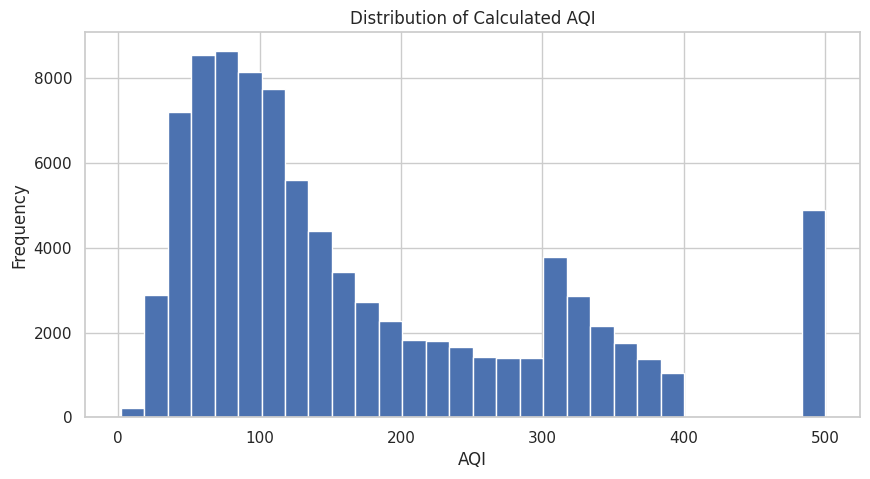

In [ ]:
aqi_data = df.select(
    "calculated_aqi"
).dropna().toPandas()

plt.figure(figsize=(10,5))

plt.hist(
    aqi_data["calculated_aqi"],
    bins=30
)

plt.title("Distribution of Calculated AQI")
plt.xlabel("AQI")
plt.ylabel("Frequency")

plt.show()

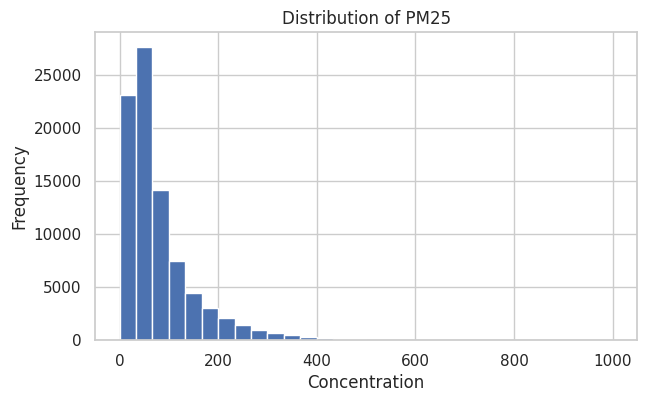

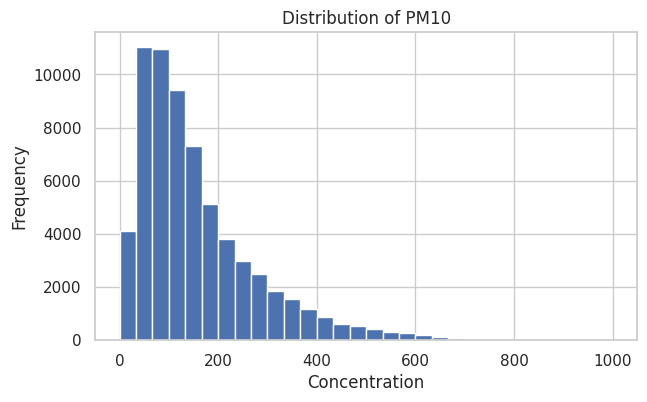

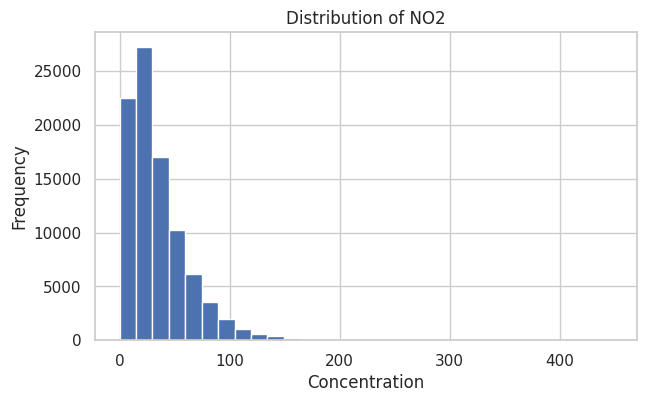

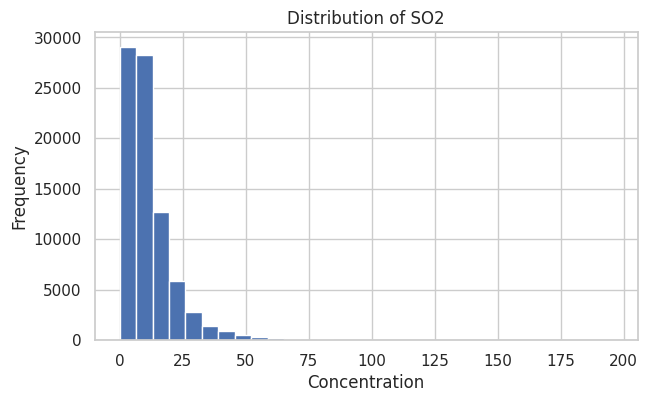

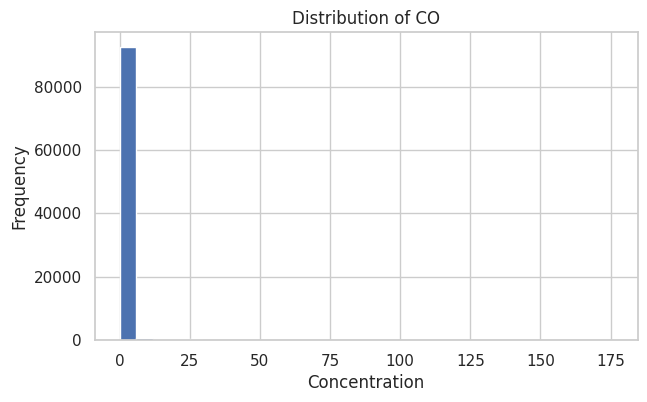

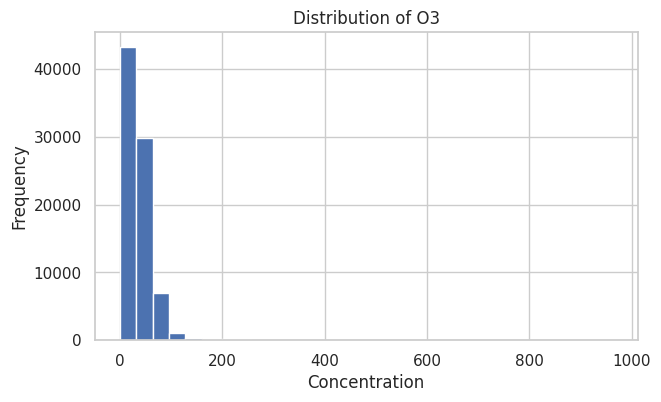

In [ ]:
for pollutant in available_pollutants:

    data = df.select(pollutant).dropna().toPandas()

    plt.figure(figsize=(7,4))

    plt.hist(data[pollutant], bins=30)

    plt.title(f"Distribution of {pollutant.upper()}")
    plt.xlabel("Concentration")
    plt.ylabel("Frequency")

    plt.show()

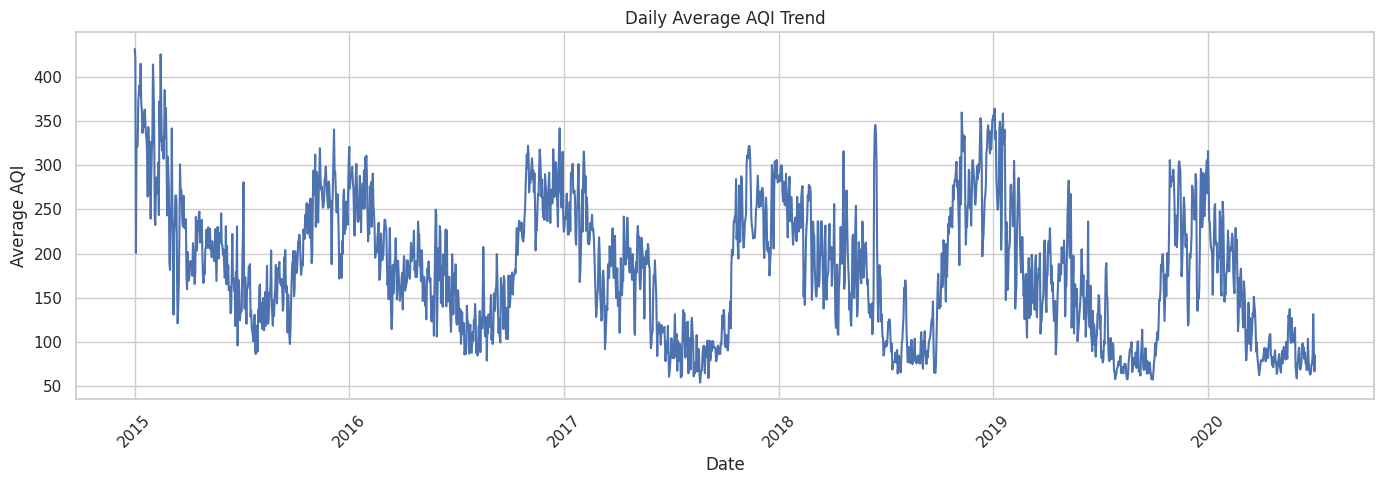

In [ ]:
daily_aqi = df.groupBy("date").agg(
    F.avg("calculated_aqi").alias("average_aqi")
).orderBy("date")

daily_pd = daily_aqi.toPandas()

plt.figure(figsize=(14,5))

plt.plot(
    daily_pd["date"],
    daily_pd["average_aqi"]
)

plt.title("Daily Average AQI Trend")
plt.xlabel("Date")
plt.ylabel("Average AQI")

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

Feature engineering

In [ ]:
df = df.withColumn(
    "year", F.year("date")
).withColumn(
    "month", F.month("date")
).withColumn(
    "day", F.dayofmonth("date")
).withColumn(
    "day_of_week", F.dayofweek("date")
).withColumn(
    "day_of_year", F.dayofyear("date")
)

df.select(
    "date", "year", "month",
    "day", "day_of_week", "day_of_year"
).show(10)

+----------+----+-----+---+-----------+-----------+
|      date|year|month|day|day_of_week|day_of_year|
+----------+----+-----+---+-----------+-----------+
|2017-12-04|2017|   12|  4|          2|        338|
|2017-12-17|2017|   12| 17|          1|        351|
|2017-12-24|2017|   12| 24|          1|        358|
|2017-12-29|2017|   12| 29|          6|        363|
|2017-12-30|2017|   12| 30|          7|        364|
|2018-01-01|2018|    1|  1|          2|          1|
|2018-01-04|2018|    1|  4|          5|          4|
|2018-01-13|2018|    1| 13|          7|         13|
|2018-01-28|2018|    1| 28|          1|         28|
|2018-01-29|2018|    1| 29|          2|         29|
+----------+----+-----+---+-----------+-----------+
only showing top 10 rows


In [ ]:
from pyspark.sql.window import Window

window_spec = Window.partitionBy(
    "station_id"
).orderBy("date")

df = df.withColumn(
    "aqi_lag_1",
    F.lag("aqi", 1).over(window_spec)
).withColumn(
    "aqi_lag_2",
    F.lag("aqi", 2).over(window_spec)
).withColumn(
    "aqi_lag_3",
    F.lag("aqi", 3).over(window_spec)
).withColumn(
    "aqi_lag_7",
    F.lag("aqi", 7).over(window_spec)
)

df.select(
    "station_id", "date", "aqi",
    "aqi_lag_1", "aqi_lag_2", "aqi_lag_7"
).show(15)

+----------+----------+-----+---------+---------+---------+
|station_id|      date|  aqi|aqi_lag_1|aqi_lag_2|aqi_lag_7|
+----------+----------+-----+---------+---------+---------+
|     AP001|2017-11-24| NULL|     NULL|     NULL|     NULL|
|     AP001|2017-11-25|184.0|     NULL|     NULL|     NULL|
|     AP001|2017-11-26|197.0|    184.0|     NULL|     NULL|
|     AP001|2017-11-27|198.0|    197.0|    184.0|     NULL|
|     AP001|2017-11-28|188.0|    198.0|    197.0|     NULL|
|     AP001|2017-11-29|173.0|    188.0|    198.0|     NULL|
|     AP001|2017-11-30|165.0|    173.0|    188.0|     NULL|
|     AP001|2017-12-01|191.0|    165.0|    173.0|     NULL|
|     AP001|2017-12-02|191.0|    191.0|    165.0|    184.0|
|     AP001|2017-12-03|227.0|    191.0|    191.0|    197.0|
|     AP001|2017-12-04|168.0|    227.0|    191.0|    198.0|
|     AP001|2017-12-05|198.0|    168.0|    227.0|    188.0|
|     AP001|2017-12-06|201.0|    198.0|    168.0|    173.0|
|     AP001|2017-12-07|252.0|    201.0| 

In [ ]:
rolling_window = Window.partitionBy(
    "station_id"
).orderBy("date").rowsBetween(-6, 0)

df = df.withColumn(
    "aqi_7day_avg",
    F.avg("aqi").over(rolling_window)
)

df.select(
    "station_id", "date", "aqi", "aqi_7day_avg"
).show(15)

+----------+----------+-----+------------------+
|station_id|      date|  aqi|      aqi_7day_avg|
+----------+----------+-----+------------------+
|     AP001|2017-11-24| NULL|              NULL|
|     AP001|2017-11-25|184.0|             184.0|
|     AP001|2017-11-26|197.0|             190.5|
|     AP001|2017-11-27|198.0|             193.0|
|     AP001|2017-11-28|188.0|            191.75|
|     AP001|2017-11-29|173.0|             188.0|
|     AP001|2017-11-30|165.0|184.16666666666666|
|     AP001|2017-12-01|191.0|185.14285714285714|
|     AP001|2017-12-02|191.0|186.14285714285714|
|     AP001|2017-12-03|227.0|190.42857142857142|
|     AP001|2017-12-04|168.0|186.14285714285714|
|     AP001|2017-12-05|198.0|187.57142857142858|
|     AP001|2017-12-06|201.0|191.57142857142858|
|     AP001|2017-12-07|252.0|             204.0|
|     AP001|2017-12-08|310.0|             221.0|
+----------+----------+-----+------------------+
only showing top 15 rows


In [ ]:
df = df.withColumn(
    "target_next_day_aqi",
    F.lead("aqi", 1).over(window_spec)
)

print("Next-day target created!")

Next-day target created!


In [ ]:
feature_columns = [
    "pm25", "pm10", "no2", "so2", "co", "o3",
    "aqi_lag_1", "aqi_lag_2",
    "aqi_lag_3", "aqi_lag_7",
    "aqi_7day_avg",
    "month", "day_of_week"
]

feature_columns = [
    c for c in feature_columns if c in df.columns
]

ml_df = df.select(
    *feature_columns,
    F.col("target_next_day_aqi").alias("label"),
    "station_id",
    "date"
).dropna()

print("ML records:", ml_df.count())
ml_df.show(10)

ML records: 45684
+------+------+-----+----+----+-----+---------+---------+---------+---------+------------------+-----+-----------+-----+----------+----------+
|  pm25|  pm10|  no2| so2|  co|   o3|aqi_lag_1|aqi_lag_2|aqi_lag_3|aqi_lag_7|      aqi_7day_avg|month|day_of_week|label|station_id|      date|
+------+------+-----+----+----+-----+---------+---------+---------+---------+------------------+-----+-----------+-----+----------+----------+
| 46.66|147.31|18.83|9.71|0.48|73.22|    168.0|    320.0|    295.0|    237.0|250.57142857142858|    3|          6|108.0|     BR005|2020-03-06|
| 53.59|114.05|38.69|7.66|0.66|43.18|    141.0|    168.0|    320.0|    310.0|221.71428571428572|    3|          7|152.0|     BR005|2020-03-07|
| 76.28|208.28|50.45|6.77|0.87|34.24|    108.0|    141.0|    168.0|    289.0|202.14285714285714|    3|          1|152.0|     BR005|2020-03-08|
| 69.46|165.16|47.99|7.08|0.96|43.59|    152.0|    108.0|    141.0|    231.0|190.85714285714286|    3|          2|271.0|    

Train-test split

In [ ]:
dates = ml_df.select("date").distinct().orderBy("date")

date_list = [
    row["date"] for row in dates.collect()
]

split_index = int(len(date_list) * 0.8)

split_date = date_list[split_index]

train_df = ml_df.filter(F.col("date") < F.lit(split_date))
test_df = ml_df.filter(F.col("date") >= F.lit(split_date))

print("Training records:", train_df.count())
print("Testing records:", test_df.count())
print("Split date:", split_date)

Training records: 23407
Testing records: 22277
Split date: 2019-06-23


Train Random Forest model

In [ ]:
from pyspark.ml.feature import VectorAssembler
from pyspark.ml.regression import RandomForestRegressor
from pyspark.ml.evaluation import RegressionEvaluator

In [ ]:
assembler = VectorAssembler(
    inputCols=feature_columns,
    outputCol="features",
    handleInvalid="skip"
)

train_vector = assembler.transform(train_df)
test_vector = assembler.transform(test_df)

In [ ]:
rf = RandomForestRegressor(
    featuresCol="features",
    labelCol="label",
    numTrees=100,
    maxDepth=10,
    seed=42
)

rf_model = rf.fit(train_vector)

print("Random Forest training completed!")

Random Forest training completed!


Evaluate the model

In [ ]:
predictions = rf_model.transform(test_vector)

predictions.select(
    "label", "prediction"
).show(15)

+-----+------------------+
|label|        prediction|
+-----+------------------+
|108.0|170.82178476591048|
|152.0|  149.171228426645|
|152.0|181.64258108942656|
|271.0| 164.3532390343222|
|179.0| 237.9888805130159|
|200.0| 187.5343880109875|
|198.0|193.33059135347176|
|116.0|196.11384182051444|
| 74.0|117.20736750247987|
|163.0|133.47719123742152|
|232.0|215.03726162861938|
|237.0|  238.910776298489|
|228.0|233.49652867313497|
|178.0|218.46853572832316|
|284.0|204.31188579419094|
+-----+------------------+
only showing top 15 rows


In [ ]:
evaluator_mae = RegressionEvaluator(
    labelCol="label",
    predictionCol="prediction",
    metricName="mae"
)

evaluator_rmse = RegressionEvaluator(
    labelCol="label",
    predictionCol="prediction",
    metricName="rmse"
)

evaluator_r2 = RegressionEvaluator(
    labelCol="label",
    predictionCol="prediction",
    metricName="r2"
)

print("MAE:", evaluator_mae.evaluate(predictions))
print("RMSE:", evaluator_rmse.evaluate(predictions))
print("R2:", evaluator_r2.evaluate(predictions))

MAE: 23.780619107958046
RMSE: 41.923754798636224
R2: 0.8690429570134806


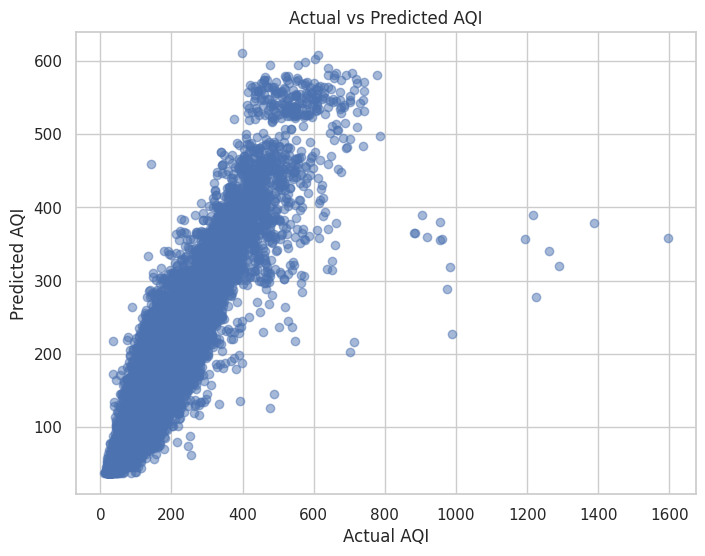

In [ ]:
prediction_pd = predictions.select(
    "label", "prediction"
).toPandas()

plt.figure(figsize=(8,6))

plt.scatter(
    prediction_pd["label"],
    prediction_pd["prediction"],
    alpha=0.5
)

plt.xlabel("Actual AQI")
plt.ylabel("Predicted AQI")
plt.title("Actual vs Predicted AQI")

plt.show()

,Feature,Importance
0,pm25,0.295990
10,aqi_7day_avg,0.265100
1,pm10,0.240766
6,aqi_lag_1,0.065387
7,aqi_lag_2,0.055650
8,aqi_lag_3,0.019330
9,aqi_lag_7,0.012642
4,co,0.012104
5,o3,0.011907
2,no2,0.007178


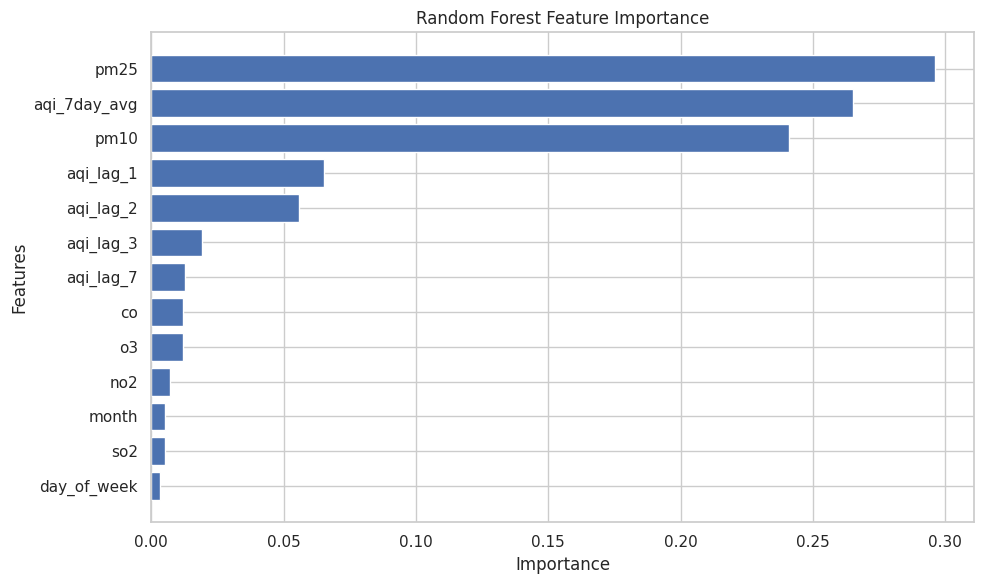

In [ ]:
importance = rf_model.featureImportances

importance_df = pd.DataFrame({
    "Feature": feature_columns,
    "Importance": importance.toArray()
})

importance_df = importance_df.sort_values(
    by="Importance",
    ascending=False
)

display(importance_df)

plt.figure(figsize=(10,6))

plt.barh(
    importance_df["Feature"],
    importance_df["Importance"]
)

plt.xlabel("Importance")
plt.ylabel("Features")
plt.title("Random Forest Feature Importance")

plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

In [ ]:

from pyspark.ml.regression import DecisionTreeRegressor, RandomForestRegressor, GBTRegressor
from pyspark.ml.evaluation import RegressionEvaluator

print("Regression algorithms imported successfully!")


Regression algorithms imported successfully!


In [ ]:

# Decision Tree model
dt = DecisionTreeRegressor(
    featuresCol="features",
    labelCol="label",
    maxDepth=10
)

dt_model = dt.fit(train_vector)

# Random Forest model
rf = RandomForestRegressor(
    featuresCol="features",
    labelCol="label",
    numTrees=100,
    maxDepth=10,
    seed=42
)

rf_model = rf.fit(train_vector)

# Gradient Boosted Tree model
gbt = GBTRegressor(
    featuresCol="features",
    labelCol="label",
    maxIter=50,
    maxDepth=5,
    seed=42
)

gbt_model = gbt.fit(train_vector)

print("All three models trained successfully!")


All three models trained successfully!


In [ ]:

dt_predictions = dt_model.transform(test_vector)
rf_predictions = rf_model.transform(test_vector)
gbt_predictions = gbt_model.transform(test_vector)

print("Predictions generated for all three models!")


Predictions generated for all three models!


In [ ]:

models = {
    "Decision Tree": dt_predictions,
    "Random Forest": rf_predictions,
    "Gradient Boosted Tree": gbt_predictions
}

evaluator_mae = RegressionEvaluator(
    labelCol="label",
    predictionCol="prediction",
    metricName="mae"
)

evaluator_rmse = RegressionEvaluator(
    labelCol="label",
    predictionCol="prediction",
    metricName="rmse"
)

evaluator_r2 = RegressionEvaluator(
    labelCol="label",
    predictionCol="prediction",
    metricName="r2"
)

comparison_results = []

for model_name, predictions in models.items():

    mae = evaluator_mae.evaluate(predictions)
    rmse = evaluator_rmse.evaluate(predictions)
    r2 = evaluator_r2.evaluate(predictions)

    comparison_results.append({
        "Model": model_name,
        "MAE": mae,
        "RMSE": rmse,
        "R2": r2
    })

comparison_df = pd.DataFrame(comparison_results)

display(comparison_df.round(4))


,Model,MAE,RMSE,R2
0,Decision Tree,25.9848,47.6570,0.8308
1,Random Forest,23.7806,41.9238,0.8690
2,Gradient Boosted Tree,24.3536,43.2775,0.8604


In [ ]:

from pyspark.sql.window import Window
from pyspark.sql import functions as F

window_spec = Window.partitionBy("station_id").orderBy("date")

date_check = (
    df
    .withColumn("next_date", F.lead("date", 1).over(window_spec))
    .withColumn("date_difference", F.datediff("next_date", "date"))
    .filter(F.col("next_date").isNotNull())
)

date_check.groupBy("date_difference").count().orderBy("date_difference").show(20)


+---------------+------+
|date_difference| count|
+---------------+------+
|              1|107925|
+---------------+------+



In [ ]:
# Create a persistence baseline using today's AQI (which is aqi_lag_1 in ml_df)
baseline_predictions = (
    ml_df
    .withColumnRenamed("aqi_lag_1", "prediction")
)

# Keep only the test-period dates
test_dates = test_vector.select("date").distinct()

baseline_test = baseline_predictions.join(
    test_dates,
    on="date",
    how="inner"
).select("label", "prediction")

# Evaluate baseline
baseline_mae = RegressionEvaluator(
    labelCol="label",
    predictionCol="prediction",
    metricName="mae"
).evaluate(baseline_test)

baseline_rmse = RegressionEvaluator(
    labelCol="label",
    predictionCol="prediction",
    metricName="rmse"
).evaluate(baseline_test)

baseline_r2 = RegressionEvaluator(
    labelCol="label",
    predictionCol="prediction",
    metricName="r2"
).evaluate(baseline_test)

print("Baseline Model Results")
print("MAE:", baseline_mae)
print("RMSE:", baseline_rmse)
print("R2:", baseline_r2)

Baseline Model Results
MAE: 39.23544462898954
RMSE: 65.28554274756092
R2: 0.6824277445045699


In [ ]:

# Save the trained Random Forest model

rf_model.write().overwrite().save(
    "/dbfs/FileStore/aqi_project/random_forest_model"
)

print("Random Forest model saved successfully!")


Random Forest model saved successfully!


In [ ]:

feature_columns = [
    "pm25",
    "pm10",
    "no2",
    "so2",
    "co",
    "o3",
    "aqi_lag_1",
    "aqi_lag_2",
    "aqi_lag_3",
    "aqi_lag_7",
    "aqi_7day_avg",
    "month",
    "day_of_week"
]

with open("feature_columns.txt", "w") as f:
    f.write("\n".join(feature_columns))

print("Feature columns saved!")


Feature columns saved!


In [ ]:

import pandas as pd

results = pd.DataFrame({
    "Model": [
        "Baseline",
        "Decision Tree",
        "Random Forest",
        "Gradient Boosted Tree"
    ],
    "MAE": [
        39.2354,
        25.9848,
        23.7806,
        24.3536
    ],
    "RMSE": [
        65.2855,
        47.6570,
        41.9238,
        43.2775
    ],
    "R2": [
        0.6824,
        0.8308,
        0.8690,
        0.8604
    ]
})

results.to_csv("model_metrics.csv", index=False)


In [ ]:
import os
import shutil
import pandas as pd

# ------------------------------------------------
# STEP 1: Create a folder for the handover files
# ------------------------------------------------

folder = "/content/AQI_Streamlit_Handover"

os.makedirs(folder, exist_ok=True)

print("Handover folder created!")

# ------------------------------------------------
# STEP 2: Save the trained Random Forest model
# ------------------------------------------------

model_path = "/content/AQI_Streamlit_Handover/random_forest_model"

rf_model.write().overwrite().save(model_path)

print("Random Forest model saved!")

# ------------------------------------------------
# STEP 3: Save the feature column names
# ------------------------------------------------

feature_columns = [
    "pm25",
    "pm10",
    "no2",
    "so2",
    "co",
    "o3",
    "aqi_lag_1",
    "aqi_lag_2",
    "aqi_lag_3",
    "aqi_lag_7",
    "aqi_7day_avg",
    "month",
    "day_of_week"
]

with open(folder + "/feature_columns.txt", "w") as f:
    f.write("\n".join(feature_columns))

print("Feature columns saved!")

# ------------------------------------------------
# STEP 4: Save model evaluation results
# ------------------------------------------------

results = pd.DataFrame({
    "Model": [
        "Baseline",
        "Decision Tree",
        "Random Forest",
        "Gradient Boosted Tree"
    ],
    "MAE": [
        39.2354,
        25.9848,
        23.7806,
        24.3536
    ],
    "RMSE": [
        65.2855,
        47.6570,
        41.9238,
        43.2775
    ],
    "R2": [
        0.6824,
        0.8308,
        0.8690,
        0.8604
    ]
})

results.to_csv(folder + "/model_metrics.csv", index=False)

print("Model metrics saved!")

# ------------------------------------------------
# STEP 5: Save sample input data
# ------------------------------------------------

sample_data = (
    ml_df
    .select(*feature_columns)
    .dropna()
    .limit(5)
    .toPandas()
)

sample_data.to_csv(folder + "/sample_input.csv", index=False)

print("Sample input data saved!")

# ------------------------------------------------
# STEP 6: Save model details
# ------------------------------------------------

details = """
PROJECT: Big Data-Driven AQI Prediction System

SELECTED MODEL:
Random Forest Regressor

PREDICTION:
Next-day AQI prediction

MODEL PERFORMANCE:
MAE  = 23.7806
RMSE = 41.9238
R2   = 0.8690

FEATURES:
pm25, pm10, no2, so2, co, o3,
aqi_lag_1, aqi_lag_2, aqi_lag_3,
aqi_lag_7, aqi_7day_avg, month, day_of_week

IMPORTANT:
The model requires 13 features in the exact order
provided in feature_columns.txt.

Historical AQI values are required to calculate
the lag and rolling-average features.

The rolling average includes the current day's AQI.
The current day's pollutant measurements and AQI
history are assumed to be available at prediction time.
"""

with open(folder + "/model_details.txt", "w") as f:
    f.write(details)

print("Model details saved!")

# ------------------------------------------------
# STEP 7: Create ZIP file
# ------------------------------------------------

zip_path = "/content/AQI_Streamlit_Handover.zip"

if os.path.exists(zip_path):
    os.remove(zip_path)

shutil.make_archive(
    "/content/AQI_Streamlit_Handover",
    "zip",
    folder
)

print("ZIP file created successfully in /content!")

Handover folder created!
Random Forest model saved!
Feature columns saved!
Model metrics saved!
Sample input data saved!
Model details saved!
ZIP file created successfully in /content!


In [ ]:
from google.colab import files

# Trigger browser download of the handover ZIP archive directly
files.download("/content/AQI_Streamlit_Handover.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:

print("Training data available:", "train_vector" in globals())
print("Testing data available:", "test_vector" in globals())
print("Cleaned dataset available:", "df" in globals())

print("\nTraining columns:")
print(train_vector.columns)

print("\nTesting columns:")
print(test_vector.columns)


Training data available: True
Testing data available: True
Cleaned dataset available: True

Training columns:
['pm25', 'pm10', 'no2', 'so2', 'co', 'o3', 'aqi_lag_1', 'aqi_lag_2', 'aqi_lag_3', 'aqi_lag_7', 'aqi_7day_avg', 'month', 'day_of_week', 'label', 'station_id', 'date', 'features']

Testing columns:
['pm25', 'pm10', 'no2', 'so2', 'co', 'o3', 'aqi_lag_1', 'aqi_lag_2', 'aqi_lag_3', 'aqi_lag_7', 'aqi_7day_avg', 'month', 'day_of_week', 'label', 'station_id', 'date', 'features']


In [ ]:

import pandas as pd
import numpy as np
import joblib
import os

from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error
from sklearn.metrics import mean_squared_error, r2_score

# Same 13 features used in your original model
feature_columns = [
    "pm25",
    "pm10",
    "no2",
    "so2",
    "co",
    "o3",
    "aqi_lag_1",
    "aqi_lag_2",
    "aqi_lag_3",
    "aqi_lag_7",
    "aqi_7day_avg",
    "month",
    "day_of_week"
]

# Convert Spark training and testing data to Pandas
train_pdf = train_vector.select(
    *feature_columns, "label"
).toPandas()

test_pdf = test_vector.select(
    *feature_columns, "label"
).toPandas()

# Separate input features and target
X_train = train_pdf[feature_columns]
y_train = train_pdf["label"]

X_test = test_pdf[feature_columns]
y_test = test_pdf["label"]

print("Training records:", len(X_train))
print("Testing records:", len(X_test))


Training records: 23407
Testing records: 22277


In [ ]:

sk_rf_model = RandomForestRegressor(
    n_estimators=100,
    max_depth=10,
    random_state=42,
    n_jobs=-1
)

sk_rf_model.fit(X_train, y_train)

# Make predictions
predictions = sk_rf_model.predict(X_test)

# Evaluate
mae = mean_absolute_error(y_test, predictions)
rmse = np.sqrt(mean_squared_error(y_test, predictions))
r2 = r2_score(y_test, predictions)

print("Scikit-learn Random Forest Results")
print("----------------------------------")
print("MAE:", mae)
print("RMSE:", rmse)
print("R2:", r2)


Scikit-learn Random Forest Results
----------------------------------
MAE: 22.93482004333551
RMSE: 40.27058407351928
R2: 0.8791673298109219


In [ ]:

# Create project folder
output_folder = "/content/AQI_Streamlit_Handover"

os.makedirs(output_folder, exist_ok=True)

# Save trained model
joblib.dump(
    sk_rf_model,
    output_folder + "/random_forest_model.pkl"
)

print("PKL model saved successfully!")


PKL model saved successfully!


In [ ]:

# Save feature names in the correct order
with open(output_folder + "/feature_columns.txt", "w") as f:
    f.write("\n".join(feature_columns))

# Save the new Scikit-learn model metrics
metrics_df = pd.DataFrame({
    "Metric": ["MAE", "RMSE", "R2"],
    "Value": [mae, rmse, r2]
})

metrics_df.to_csv(
    output_folder + "/model_metrics.csv",
    index=False
)

print("Feature columns and metrics saved!")


Feature columns and metrics saved!


In [ ]:

# Select the historical data needed by Streamlit
historical_columns = [
    "station_id",
    "date",
    "pm25",
    "pm10",
    "no2",
    "so2",
    "co",
    "o3",
    "aqi"
]

# Convert cleaned Spark DataFrame to Pandas
historical_pdf = df.select(
    *historical_columns
).toPandas()

# Save as CSV
historical_pdf.to_csv(
    output_folder + "/historical_aqi_data.csv",
    index=False
)

print("Historical AQI data saved!")
print("Total records:", len(historical_pdf))


Historical AQI data saved!
Total records: 108035


In [ ]:

import shutil
from google.colab import files

# Create ZIP
zip_path = shutil.make_archive(
    "/content/AQI_Streamlit_Handover",
    "zip",
    output_folder
)

print("ZIP file created:", zip_path)

# Download to your computer
files.download(zip_path)


ZIP file created: /content/AQI_Streamlit_Handover.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>